# Imitation y Métricas
Permutación espectral de coeficientes complejos (`rfft`) para ocultar 5 mensajes secretos bajo el espectro de un Target.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.io import wavfile
from scipy.fft import rfft, irfft, rfftfreq

# ====== AJUSTA ESTAS RUTAS A TUS ARCHIVOS ======
TARGET_FILE  = "target.wav"
SECRET_FILES = [f"secret{i}.wav" for i in range(1, 6)]
OUT = Path("resultados")
for sub in ("encoded", "keys", "recovered"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

## 1. Carga y verificación

In [4]:
def cargar_wav(ruta):
    """Devuelve (fs, señal mono float en [-1,1] aprox)."""
    fs, x = wavfile.read(ruta)
    if x.dtype.kind in "iu":                      # enteros -> escala [-1, 1]
        x = x.astype(np.float64) / np.iinfo(x.dtype).max
    else:
        x = x.astype(np.float64)
    if x.ndim > 1:                                # estéreo -> mono
        x = x.mean(axis=1)
    return fs, x

fs_t, target = cargar_wav(TARGET_FILE)
secretos = {}
for i, f in enumerate(SECRET_FILES, start=1):
    fs_s, s = cargar_wav(f)
    assert fs_s == fs_t, f"{f}: fs distinta ({fs_s} vs {fs_t})"
    assert len(s) == len(target), f"{f}: {len(s)} muestras vs {len(target)} del Target"
    secretos[i] = s
print("fs =", fs_t, "Hz | N =", len(target), "muestras | duración =", round(len(target)/fs_t, 2), "s")

fs = 44100 Hz | N = 383184 muestras | duración = 8.69 s


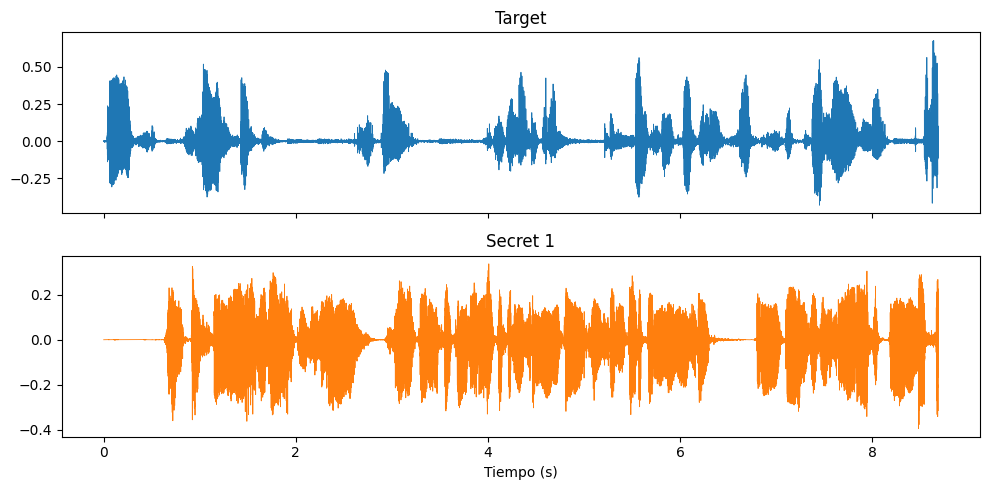

In [5]:
t = np.arange(len(target)) / fs_t
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(t, target, lw=.6);      ax[0].set_title("Target")
ax[1].plot(t, secretos[1], lw=.6, c="tab:orange"); ax[1].set_title("Secret 1")
ax[1].set_xlabel("Tiempo (s)"); plt.tight_layout(); plt.savefig(OUT/"Grafica_tiempo.png", dpi=150); plt.show()

## 2. Espectros de magnitud

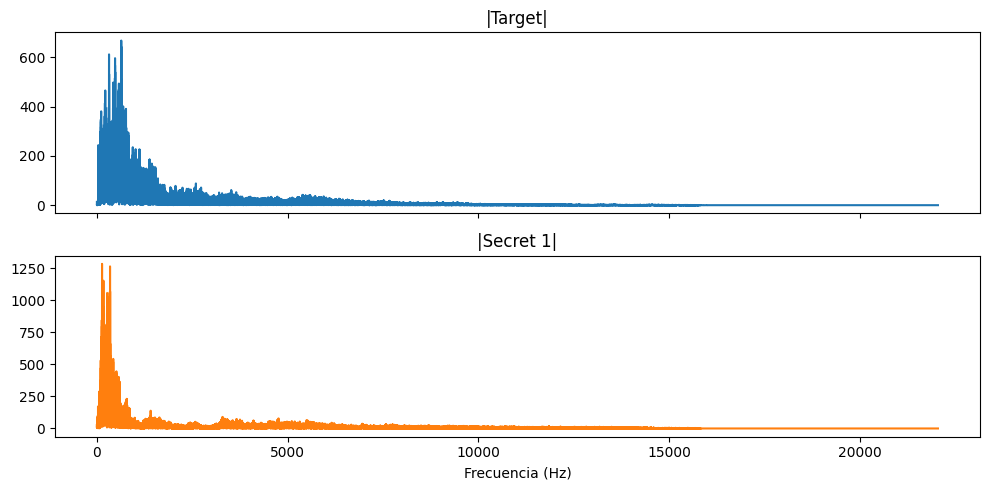

In [6]:
T = rfft(target); S1 = rfft(secretos[1]); f = rfftfreq(len(target), 1/fs_t)
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(f, np.abs(T));  ax[0].set_title("|Target|")
ax[1].plot(f, np.abs(S1), c="tab:orange"); ax[1].set_title("|Secret 1|")
ax[1].set_xlabel("Frecuencia (Hz)"); plt.tight_layout(); plt.savefig(OUT/"Grafica_espectro.png", dpi=150); plt.show()

## 3. Imitation: permutación espectral

Con `P` = posiciones permutables (todas menos DC y, si N es par, Nyquist):

- `I1 = argsort(|S[P]|)`, `I2 = argsort(|T[P]|)`
- El coeficiente de rango *r* del Secret pasa a la posición donde el Target tiene rango *r*: `K[P[I2]] = P[I1]`
- `E = S[K]` (se mueven números complejos completos, no se altera ninguno)

Reverse hace `X_rec[K] = E`, que es exactamente la inversa.

In [7]:
def imitation(secret, target):
    N = len(secret)
    S, T = rfft(secret), rfft(target)
    M = len(S)                                   # N//2 + 1 coeficientes
    # posiciones permutables: sin DC (0) y sin Nyquist (último si N es par)
    P = np.arange(1, M - 1) if N % 2 == 0 else np.arange(1, M)

    I1 = np.argsort(np.abs(S[P]))
    I2 = np.argsort(np.abs(T[P]))

    K = np.arange(M)                             # identidad: DC y Nyquist quedan fijos
    K[P[I2]] = P[I1]

    E = S[K]
    encoded = irfft(E, n=N)
    return encoded, K, E, S

def guardar_clave(K, ruta):
    # encabezado de 1 línea porque Reverse usa skiprows=1
    np.savetxt(ruta, K, fmt="%d", delimiter=",", header="key", comments="")

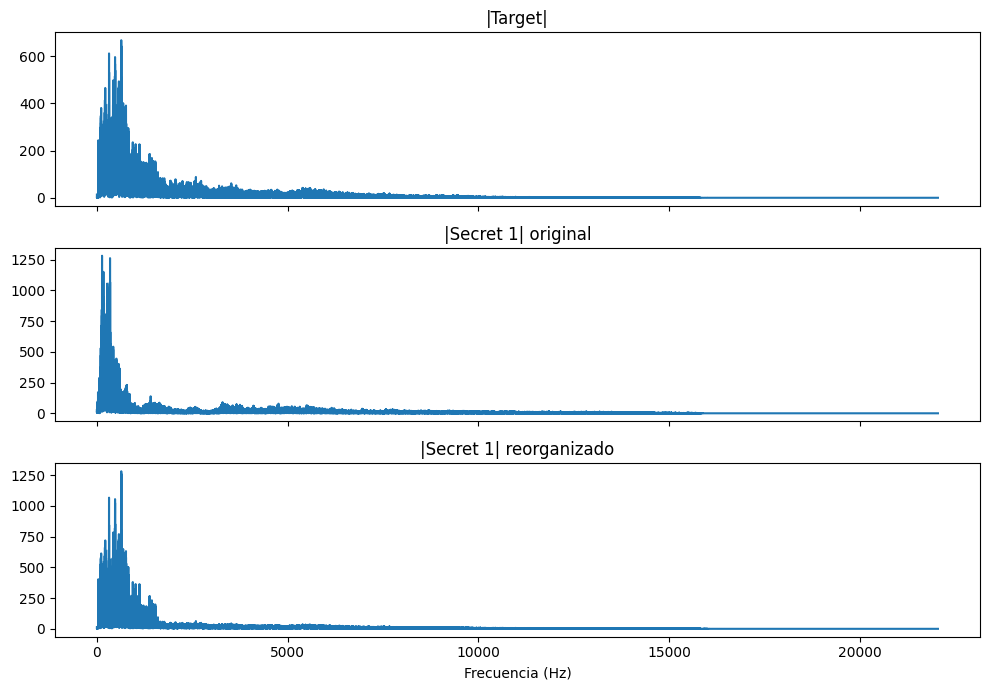

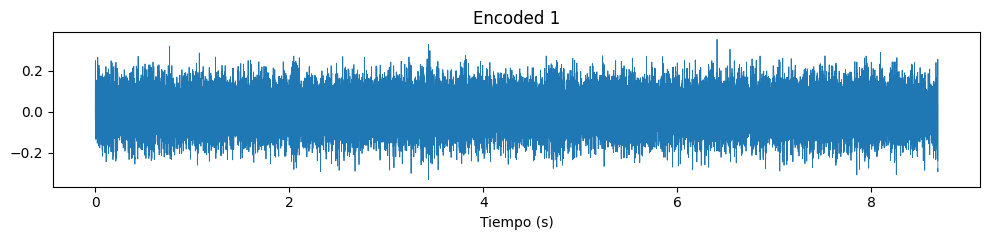

In [8]:
encoded1, K1, E1, S1 = imitation(secretos[1], target)
fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
ax[0].plot(f, np.abs(T));  ax[0].set_title("|Target|")
ax[1].plot(f, np.abs(S1)); ax[1].set_title("|Secret 1| original")
ax[2].plot(f, np.abs(E1)); ax[2].set_title("|Secret 1| reorganizado")
ax[2].set_xlabel("Frecuencia (Hz)"); plt.tight_layout(); plt.savefig(OUT/"Grafica_espectro_ordenado.png", dpi=150); plt.show()

plt.figure(figsize=(10, 2.5)); plt.plot(t, encoded1, lw=.6)
plt.title("Encoded 1"); plt.xlabel("Tiempo (s)"); plt.tight_layout(); plt.savefig(OUT/"Grafica_encoded.png", dpi=150); plt.show()

## 4-5. Codificar los cinco secretos
Se guarda en **float32** (sin normalizar) para no perder escala ni cuantizar.

In [9]:
for i, s in secretos.items():
    enc, K, _, _ = imitation(s, target)
    wavfile.write(OUT/"encoded"/f"encoded_{i}.wav", fs_t, enc.astype(np.float32))
    guardar_clave(K, OUT/"keys"/f"FFT_key_{i}.csv")
    print(f"Secret {i}: encoded_{i}.wav y FFT_key_{i}.csv guardados")

Secret 1: encoded_1.wav y FFT_key_1.csv guardados
Secret 2: encoded_2.wav y FFT_key_2.csv guardados
Secret 3: encoded_3.wav y FFT_key_3.csv guardados
Secret 4: encoded_4.wav y FFT_key_4.csv guardados
Secret 5: encoded_5.wav y FFT_key_5.csv guardados


## Parte III. Métricas

In [11]:
def snr_db(x, x_hat):
    return 10 * np.log10(np.sum(x**2) / np.sum((x - x_hat)**2))

def pearson(x, x_hat):
    return np.corrcoef(x, x_hat)[0, 1]

filas = []
for i in secretos:
    x = secretos[i]
    # el WAV se guardó en float32: comparamos contra el secreto tal como quedaría en float32
    x_hat = np.asarray(wavfile.read(OUT/"recovered"/f"recovered_{i}.wav")[1], dtype=np.float64)
    filas.append({"Mensaje secreto": f"Secret {i}", "SNR (dB)": snr_db(x, x_hat), "Correlación de Pearson": pearson(x, x_hat)})
tabla = pd.DataFrame(filas)
tabla.to_csv(OUT/"metricas.csv", index=False)
print(tabla.to_markdown(index=False, floatfmt=".4f"))

| Mensaje secreto   |   SNR (dB) |   Correlación de Pearson |
|:------------------|-----------:|-------------------------:|
| Secret 1          |   152.4170 |                   1.0000 |
| Secret 2          |   152.2052 |                   1.0000 |
| Secret 3          |   152.4091 |                   1.0000 |
| Secret 4          |   152.3719 |                   1.0000 |
| Secret 5          |   152.2641 |                   1.0000 |


## Análisis (completa con TUS números)
- ¿Qué secreto tiene mejor SNR/correlación? ¿Son parecidos los cinco?
- Una permutación es exactamente reversible en los números, pero el audio se guarda en un archivo con precisión finita (float32 tiene ~24 bits de mantisa; con int16 serían 16 bits y el error sería mucho mayor). Esos redondeos se acumulan en la `irfft`, y por eso SNR es alto pero finito y Pearson ≈ 1 pero no exactamente 1.
- SNR mide error de energía absoluto; Pearson mide similitud de forma e ignora escala y offset. Compáralos: un Pearson ≈ 1 con SNR más bajo indicaría error pequeño pero no nulo de amplitud.